# Machine Learning Study - Learning Different Models 

## Basics 

In this notebook we will cover the fundamental machine learning models:
- Linear Regression
- Logistic Regression
- k-means
- k-nearest neighbors
- decision tree (Gini or entropy)
- 2 layer Neural Networks (NN)
    - with backpropogation

For each model we cover:
1. What is the objective of the the model and what is the learning procedure?
2. What does it assume about the data?
3. What are the main 2-3 hyperparameters?
4. How useful is it under class imbalance?
5. What does inference cost, and how would you serve and monitor it?

#### **Data Disclaimer**

For each model we will use base dataset provided by scikit-learn(sklearn) and seaborn (sns). If a custom dataset is used, it will be noted as such. Links and references will be provided.

#### **Base Imports**


In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **2. Logistic Regression**

Logistic regression is a ml-model that predicts the probability that an input belongs to a class. Even though it has "regression" in the name, it is a **classification** model. For binary labels $y\in\{0,1\}$ and an array x s.t. $x\in{\mathbb{R}^n}$, we pass a linear model through the sigmoid function $\sigma$:

$$ P(y=1 \mid x) = \sigma(\beta^Tx + \beta_0) = \frac{1}{1+e^{-(\beta^Tx + \beta_0)}} \text{ where } x\in{\mathbb{R}^n}$$

For logistic regression:
1. The goal of the logistic regression model is to estimate the probability $p$ that some input $x$ is in class 1. The learning procedure minimizes log loss (binary cross-entropy), usually with a regularization penalty $\lambda R(\beta)$ to keep the coefficients from getting too big:
$$L = -\frac{1}{n}\sum_{i=1}^n \left[y_i\log(p_i) + (1-y_i)\log(1-p_i)\right] + \lambda R(\beta)$$
Unlike linear regression there is no closed form solution, so an iterative solver (e.g. L-BFGS, SAGA) updates the weights until it converges. A threshold (default 0.5) turns the probability into a label. With more than 2 classes we use multinomial logistic regression (softmax instead of sigmoid).

2. The main thing assumed is that the log-odds are linear in the features: $\log(\frac{p}{1-p}) = \beta^Tx + \beta_0$. The target must be categorical, rows should be independent, and categorical features need to be encoded as numbers. It does **not** assume normal features or constant error variance. Scaling the features helps the solver converge and makes regularization fair across features.

3. The main hyperparameters are:
    - `C`: inverse regularization strength. Smaller $C$ = more shrinking of the coefficients, larger $C$ = fits the training data closer.
    - `penalty` / `l1_ratio`: the type of regularization. L2 shrinks coefficients, L1 can set some to 0 (feature selection), elastic net mixes both.
    - `class_weight`: how much each class counts in the loss. `'balanced'` weights classes inversely to how often they show up.

4. Logistic regression is a good baseline under class imbalance, but the default 0.5 threshold can ignore the minority class. Example if 99% of patients are healthy and 1% are sick, a model that always predicts healthy is 99% accurate and completely useless. We can fix this with `class_weight='balanced'` or by lowering the threshold, and we judge it with precision, recall, and F1 instead of accuracy.

5. The inference cost for a logistic regression model is almost none, it is one dot product and a sigmoid, $O(n)$ for $n$ features. It is easy to deploy to something like an API, but the scaler and model should be saved together (a pipeline) so new data gets the same preprocessing. Like linear regression it falls subject to data drift, so we should monitor the input features and the proportion of predicted classes, and retrain with updated data when they shift.


#### **The Sigmoid Function**

Move the sliders to explore $p = \sigma(wx + b) = 1 / (1 + e^{-(wx+b)})$.

- **Weight $w$** controls steepness and direction. A negative weight makes the curve decrease; $w=0$ makes it flat.
- **Bias $b$** changes the probability at $x=0$. For $w \ne 0$, the curve crosses the dashed $p=0.5$ line at $x=-b/w$.
- Try $w=1, b=0$, then change one parameter at a time. These are model parameters learned during training; here you control them by hand.

Run the cell below. If packages are missing, run `%pip install plotly ipywidgets` in a separate cell, then rerun it.


In [ ]:
import math
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display

# Keep this demo independent of the dataset and model below.
sigmoid_x = [i / 20 for i in range(-200, 201)]

def plot_sigmoid(w=1.0, b=0.0):
    probabilities = [1 / (1 + math.exp(-(w * x + b))) for x in sigmoid_x]
    fig = go.Figure(go.Scatter(
        x=sigmoid_x, y=probabilities, mode="lines",
        line=dict(width=3), name="P(y=1 | x)",
        hovertemplate="x=%{x:.2f}<br>Probability=%{y:.3f}<extra></extra>",
    ))
    fig.add_hline(y=0.5, line_dash="dash", line_color="gray")
    fig.update_layout(
        title=f"Sigmoid: p = 1 / (1 + exp(-({w:.1f}x + {b:.1f})))",
        xaxis=dict(title="Input x", range=[-10, 10]),
        yaxis=dict(title="Probability P(y=1 | x)", range=[-0.02, 1.02]),
        template="plotly_white", height=420, showlegend=False,
    )
    # Use the notebook's Plotly renderer instead of scripts embedded in HTML.
    display({
        "application/vnd.plotly.v1+json": fig.to_plotly_json(),
        "text/plain": "Interactive sigmoid plot (requires a Plotly notebook renderer).",
    }, raw=True)

sigmoid_controls = widgets.interactive(
    plot_sigmoid,
    w=widgets.FloatSlider(value=1, min=-5, max=5, step=0.1,
                          description="Weight w", continuous_update=False),
    b=widgets.FloatSlider(value=0, min=-10, max=10, step=0.1,
                          description="Bias b", continuous_update=False),
)
display(sigmoid_controls)


interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='Weight w', max=5.0, min=-5.…

#### **Data Set for Logistic Regression**

We will load the sklearn [Breast Cancer dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) and try to predict if a tumor is malignant or benign from 30 numeric measurements.

Note: sklearn labels malignant as **0** and benign as **1**. Since we care about catching malignant tumors, we flip it so **malignant = 1** (the positive class).

In [16]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
cancer = data.frame.assign(malignant=(data.target == 0).astype(int)).drop(columns='target')
print(cancer.shape)
cancer['malignant'].value_counts()

(569, 31)


malignant
0    357
1    212
Name: count, dtype: int64

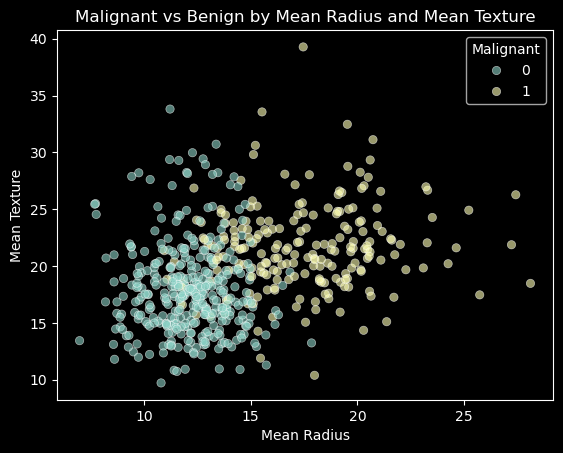

In [17]:
sns.scatterplot(data=cancer, x='mean radius', y='mean texture', hue='malignant', alpha=0.6)
plt.title("Malignant vs Benign by Mean Radius and Mean Texture")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.legend(title="Malignant")
plt.show()

#### **Splitting the data and modeling**

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler # For standardizing features
from sklearn.pipeline import make_pipeline # to create a recurring pipeline for the data
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

features = data.feature_names
X = np.array(cancer[features])
y = np.array(cancer['malignant'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, random_state=42, stratify=y) # stratify to make sure even splits of labeled data

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)
#Model stats
print(f'Intercept: {model[-1].intercept_[0]:.4f}')

# Make predictions
y_pred = model.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}') #Overall Stats but can hide things
print(f'Precision: {precision_score(y_test, y_pred):.4f}')# Matters when false alarms are bad, high means diagnosis is correct
print(f'Recall: {recall_score(y_test, y_pred):.4f}')# Matters when missed positive are bad, high means most positives are caught
print(f'F1: {f1_score(y_test, y_pred):.4f}') #helps when both precision and recall matter. It ignores true negatives and does not account for different costs of mistakes.

Intercept: -0.3480
Accuracy: 0.9708
Precision: 0.9836
Recall: 0.9375
F1: 0.9600


#### **Evaluating the model**

Accuracy on its own doesn't tell us much. We check:
1. **Coefficients**: there are 30 features, so we look at the biggest ones.
2. **Baseline**: does the model beat always predicting the majority class?
3. **Train vs test**: a big gap means overfitting.
4. **Cross-validation**: is the score stable across different splits?
5. **Confusion matrix**: what kind of mistakes does it make?
6. **Worst predictions**: where is it confidently wrong?

In [19]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import log_loss
from sklearn.model_selection import cross_val_score

# 1. Biggest coefficients (features are scaled so they are comparable)
coefs = pd.Series(model[-1].coef_[0], index=features)
print(coefs.sort_values(key=abs, ascending=False).head(5).round(4), '\n')

# 2. Baseline: always predict the most common class
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

def scores(m, X, y):
    p = m.predict(X)
    return {'Accuracy': accuracy_score(y, p),
            'Precision': precision_score(y, p, zero_division=0),
            'Recall': recall_score(y, p),
            'F1': f1_score(y, p),
            'Log Loss': log_loss(y, m.predict_proba(X))}

# 3. Find difference between our model and chance
report = pd.DataFrame({
    'baseline (test)': scores(baseline, X_test, y_test),
    'model (train)': scores(model, X_train, y_train),
    'model (test)': scores(model, X_test, y_test)
})

print(report.round(4), '\n')

# 4. Cross Validation
cv = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression()), X, y, cv=5, scoring='f1')
print(f'5-fold CV F1: {cv.mean():.3f} ± {cv.std():.3f}')

worst texture        1.3843
radius error         1.2051
worst symmetry       1.0857
area error           0.9121
compactness error   -0.9046
dtype: float64 

           baseline (test)  model (train)  model (test)
Accuracy            0.6257         0.9874        0.9708
Precision           0.0000         1.0000        0.9836
Recall              0.0000         0.9662        0.9375
F1                  0.0000         0.9828        0.9600
Log Loss           13.4900         0.0566        0.0675 

5-fold CV F1: 0.974 ± 0.009


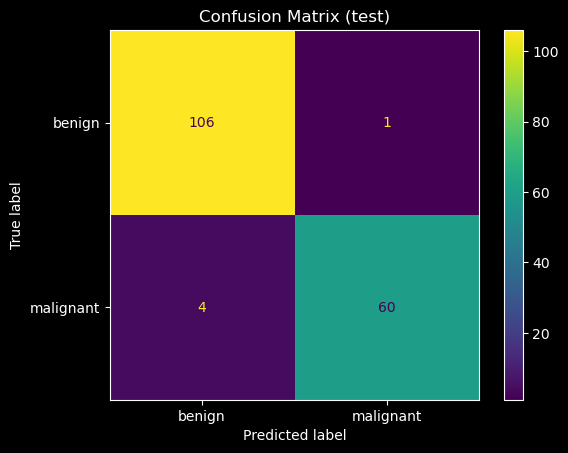

,mean radius,mean texture,mean perimeter,actual,predicted,p_malignant,confidence
148,13.80,15.79,90.43,1,0,0.059,0.441
135,14.22,23.12,94.37,1,0,0.243,0.257
46,13.86,16.93,90.96,1,0,0.373,0.127
29,13.38,30.72,86.34,0,1,0.537,0.037
21,15.12,16.68,98.78,1,0,0.482,0.018


In [ ]:
# 5. Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['benign', 'malignant'])
plt.title('Confusion Matrix (test)')
plt.show()

# 6. Worst 5 predictions (wrong and most confident)
proba = model.predict_proba(X_test)[:, 1]
errors = pd.DataFrame(X_test[:, :3], columns=features[:3]).assign(
    actual=y_test, predicted=y_pred, p_malignant=proba.round(3))
wrong = errors[errors['actual'] != errors['predicted']]
wrong.assign(confidence=np.abs(wrong['p_malignant'] - 0.5)).sort_values('confidence', ascending=False).head(5)

### Personal Learning

Termonology:
- Sigmoid $\sigma(z) = \frac{1}{1+e^{-z}}$:

    - Squishes any number into $(0, 1)$ so it can be read as a probability
    - $z = 0 \Rightarrow 0.5$, big positive $z \Rightarrow \approx 1$, big negative $z \Rightarrow \approx 0$

- Log Loss (Binary Cross-Entropy):

    - Take $-\frac{1}{n}\sum_{i=1}^n \left[y_i\log(p_i) + (1-y_i)\log(1-p_i)\right]$
    - Punishes being confidently wrong a lot more than being unsure. Lower is better.

- Confusion Matrix:

    - True Positive (TP): predicted malignant, actually malignant
    - False Positive (FP): predicted malignant, actually benign
    - False Negative (FN): predicted benign, actually malignant (the worst one here)
    - True Negative (TN): predicted benign, actually benign

- Accuracy: $\frac{TP + TN}{\text{total}}$

    - Fraction of all predictions that are right. Misleading under class imbalance.

- Precision: $\frac{TP}{TP + FP}$

    - Of everything we called malignant, how much actually was?
    - Best when false positives are expensive

- Recall: $\frac{TP}{TP + FN}$

    - Of everything that actually was malignant, how much did we catch?
    - Best when false negatives are expensive (like missing cancer)

- F1: $2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$

    - Balance of precision and recall in one number

Model Coeff:
- Each coefficient changes the **log-odds** of class 1 when $x_i$ goes up by 1 (here 1 std, since we scaled)
- $e^{\beta_i}$ is the odds ratio, ex. $\beta_i = 0.7 \Rightarrow$ odds multiply by about 2
- The intercept is the log-odds when all $x = 0$ (here the average patient, since we scaled)

Stratify:
- `stratify=y` in `train_test_split` keeps the same class ratio in train and test, so the test set isn't accidentally missing the minority class.

DummyClassifier:
- "Trains" against the data. With `strategy='most_frequent'` it always outputs the most common class. Used for validating a model. It gets decent accuracy but 0 recall, which shows why accuracy alone is a trap.

Testing:
- Show the Results of "Luck" i.e. the DummyClassifier
- Show results of model on training data to see how the model performs on already seen data.
- Show results of model on testing data to see how the model performs on not seen data.
- The difference between the 3 tell you how well the model is performing
    - Ideally training $\approx$ test; training $\ne$ DummyClassifier

Threshold:
- `predict` uses 0.5 by default. `predict_proba` gives the actual probabilities.
- Lowering the threshold catches more malignant (higher recall) but adds more false alarms (lower precision).


### **Room for optimization?**

For a logistic regression model, we can potentially optimize the model by tuning the hyperparameters `C` and `class_weight` with cross-validation. Since missing a malignant tumor is worse than a false alarm, we will tune for **recall** and keep an eye on precision.

In [8]:
# Same data and split, tune C and class_weight with 5-fold CV
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    param_grid={'logisticregression__C': [0.01, 0.1, 1, 10, 100],
                'logisticregression__class_weight': [None, 'balanced']},
    scoring='recall', cv=5)
grid.fit(X_train, y_train)
print(f'Best params: {grid.best_params_}')
print(f'Best 5-fold CV recall: {grid.best_score_:.3f}', '\n')

# Test-split comparison
print(pd.DataFrame({
    'default (C=1, no weights)': scores(model, X_test, y_test),
    'tuned (GridSearchCV)': scores(grid.best_estimator_, X_test, y_test),
}).T.round(4))

Best params: {'logisticregression__C': 10, 'logisticregression__class_weight': 'balanced'}
Best 5-fold CV recall: 0.939 

                           Accuracy  Precision  Recall    F1  Log Loss
default (C=1, no weights)    0.9708     0.9836  0.9375  0.96    0.0675
tuned (GridSearchCV)         0.9708     0.9836  0.9375  0.96    0.1415


Not much changed on the test split. The tuned model picked `C=10` with `class_weight='balanced'`, but it got the same accuracy, precision, recall, and F1, with a worse log loss (less reliable probabilities). The default model is already strong on this data, so we can leave tuning to further investigation. A next step would be lowering the threshold to trade a bit of precision for catching more malignant tumors.

### End of File